# Practical Assignment 2: Feedforward Neural Network on MNIST Digit Dataset

**Aim:** Implement Feedforward neural networks with Keras and TensorFlow on the MNIST Digit dataset.

**Key Concepts to Remember:**
1. **Input:** 784 flattened pixels (28x28 grayscale), scaled to $[0, 1]$ by dividing by `255.0`.
2. **Architecture:** Multi-Layer Perceptron (Dense layers with ReLU activation and Softmax output).
3. **Loss Function:** `sparse_categorical_crossentropy` for integer labels (0 to 9).


In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Step 1: Load and Preprocess Data
df = pd.read_csv(r'd:/workspace01/4th year/DL/LabPracticesIV_DEEP_LEARNING/dataset/MNIST/mnist_784_csv.csv', nrows=8000)
X = df.iloc[:, :-1].values.astype('float32') / 255.0  # Normalize to [0, 1]
y = df.iloc[:, -1].values.astype('int32')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}')

# Step 2: Build Feedforward Neural Network Architecture
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.summary()

# Step 3: Compile and Train Model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=1)

# Step 4: Evaluate Model
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f'\nTest Accuracy: {test_acc*100:.2f}% | Test Loss: {test_loss:.4f}')

# Classification Report & Predictions
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print('\nClassification Report:')
print(classification_report(y_test, y_pred, digits=4))


Training samples: 6400, Test samples: 1600
Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 235,146 (918.54 KB)
 Trainable params: 235,146 (918.54 KB)
 Non-trainable p

### Step 5: Plot Training & Validation Loss and Accuracy Curves

Visualizing loss and accuracy trajectories across training epochs confirms convergence and checks for overfitting.


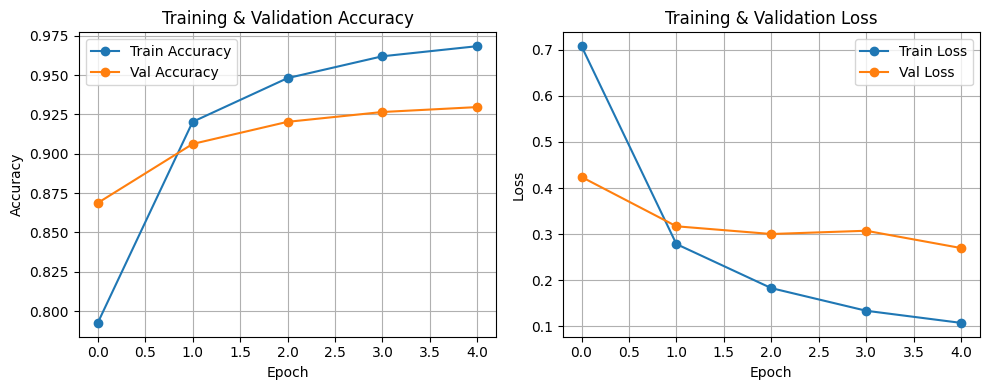

In [2]:
import matplotlib.pyplot as plt

# Step 5: Plot Training & Validation Accuracy and Loss Curves
plt.figure(figsize=(10, 4))

# Subplot 1: Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', marker='o')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Subplot 2: Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='o')
plt.plot(history.history['val_loss'], label='Val Loss', marker='o')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
